# ECG exploratory data analysis

Load an unmodified MIT-BIH Arrhythmia Database signal and its `.atr` annotations. Dataset provenance and license: [DATA_NOTICE.md](../DATA_NOTICE.md). Record 100 is the example used in the starter notebook; set `record_id` to another ID from `data/RECORDS` to inspect it.

In [1]:
from collections.abc import Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import wfdb

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").exists() and (path / "data/RECORDS").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open the notebook inside the project folder.")

record_id = "100"
record_ids = (project_root / "data/RECORDS").read_text().splitlines()
if record_id not in record_ids:
    raise ValueError(f"Unknown record ID: {record_id}")
record_path = project_root / "data/raw/mitdb-1.0.0" / record_id
record = wfdb.rdrecord(str(record_path))
annotations = wfdb.rdann(str(record_path), "atr")

print(f"Record: {record.record_name}")
print(f"Samples: {record.sig_len}, sampling rate: {record.fs} Hz")
print(f"Channels: {list(zip(record.sig_name, record.units))}")
print(f"Annotations: {len(annotations.sample)}")

Record: 100
Samples: 650000, sampling rate: 360 Hz
Channels: [('MLII', 'mV'), ('V5', 'mV')]
Annotations: 2274


## Signal with annotations

The plot uses physical signal values and sample positions from the raw files. Every `.atr` annotation in the selected time interval is marked at its sample position and labeled with its original WFDB symbol. No annotation symbols are remapped or excluded. The displayed interval is half-open: `[start_s, start_s + duration_s)`.

Select a single channel with `channel=0` or both channels with `channel=(0, 1)`. Set `layout="overlay"` for one shared axis or `layout="stacked"` for separate rows with a shared time axis. Each channel's signal, annotation markers, and symbols share a color. Both examples below use the same 10-second interval.

In [2]:
def plot_ecg_with_annotations(
    record,
    annotations,
    channel: int | Sequence[int] = 0,
    start_s=0.0,
    duration_s=10.0,
    layout="overlay",
):
    """Plot one or two ECG channels with their original `.atr` annotation symbols.

    The displayed interval is [start_s, start_s + duration_s). Each annotation
    is placed at its sample position on every selected channel, with its symbol
    to the right of the marker. A channel's signal, annotation markers, and
    annotation symbols share the same color.

    Args:
        record: WFDB Record with loaded physical signal values.
        annotations: WFDB Annotation for the same record.
        channel: Zero-based channel index or a sequence of one or two unique
            indices, such as (0, 1). Defaults to 0.
        start_s: Interval start in seconds (default: 0).
        duration_s: Interval length in seconds (default: 10).
        layout: "overlay" draws selected channels on one axis; "stacked" draws
            one channel per row with a shared time axis. Defaults to "overlay".
            Overlay requires all selected channels to use the same unit.

    Returns:
        Tuple of a Matplotlib figure and either one Axes object or an array of
        Axes objects when multiple channels are stacked.
    """
    if record.record_name != annotations.record_name:
        raise ValueError("The signal and annotations must belong to the same record.")
    if annotations.fs is not None and annotations.fs != record.fs:
        raise ValueError("The signal and annotation sampling rates differ.")
    if isinstance(channel, (int, np.integer)):
        channels = [channel]
    else:
        try:
            channels = list(channel)
        except TypeError as exc:
            raise ValueError("Channel must be an index or a sequence of indices.") from exc
    if not 1 <= len(channels) <= 2 or any(
        not isinstance(index, (int, np.integer)) or not 0 <= index < record.n_sig
        for index in channels
    ):
        raise ValueError(f"Select one or two channel indices from 0 to {record.n_sig - 1}.")
    if len(set(channels)) != len(channels):
        raise ValueError("Channel indices must be unique.")
    if layout not in ("overlay", "stacked"):
        raise ValueError('Layout must be "overlay" or "stacked".')
    if layout == "overlay" and len({record.units[index] for index in channels}) != 1:
        raise ValueError("Overlay requires matching channel units; use the stacked layout.")
    if not np.isfinite(start_s) or not np.isfinite(duration_s) or start_s < 0 or duration_s <= 0:
        raise ValueError("Use a nonnegative start and a positive, finite duration.")

    first = round(start_s * record.fs)
    last = round((start_s + duration_s) * record.fs)
    if first >= last or last > record.sig_len:
        raise ValueError(f"The interval must contain samples within 0–{record.sig_len / record.fs:.2f} s.")

    sample_indices = np.arange(first, last)
    annotation_mask = (annotations.sample >= first) & (annotations.sample < last)
    annotation_samples = annotations.sample[annotation_mask]
    annotation_symbols = np.asarray(annotations.symbol)[annotation_mask]

    rows = len(channels) if layout == "stacked" else 1
    fig, axes = plt.subplots(nrows=rows, sharex=True, figsize=(14, 4 * rows))
    plot_axes = np.atleast_1d(axes)
    for position, index in enumerate(channels):
        ax = plot_axes[position if layout == "stacked" else 0]
        signal = record.p_signal[:, index]
        line, = ax.plot(
            sample_indices / record.fs, signal[first:last], linewidth=0.8,
            color=f"C{position}", label=record.sig_name[index],
        )
        ax.scatter(
            annotation_samples / record.fs, signal[annotation_samples],
            color=line.get_color(), s=24, zorder=3,
        )
        for sample, symbol in zip(annotation_samples, annotation_symbols):
            ax.annotate(
                symbol, (sample / record.fs, signal[sample]),
                xytext=(7, 0), textcoords="offset points",
                ha="left", va="center", color=line.get_color(), fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.2),
            )

    for position, ax in enumerate(plot_axes):
        axis_channels = [channels[position]] if layout == "stacked" else channels
        names = ", ".join(record.sig_name[index] for index in axis_channels)
        ax.set(ylabel=f"Amplitude ({record.units[axis_channels[0]]})",
               title=f"Record {record.record_name}: {names}")
        ax.set_xlim(first / record.fs, last / record.fs)
        ax.margins(y=0.2)
        ax.grid(alpha=0.25)
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    plot_axes[-1].set_xlabel("Time (s)")
    fig.tight_layout()
    return fig, axes

### Example 1: both channels on one axis

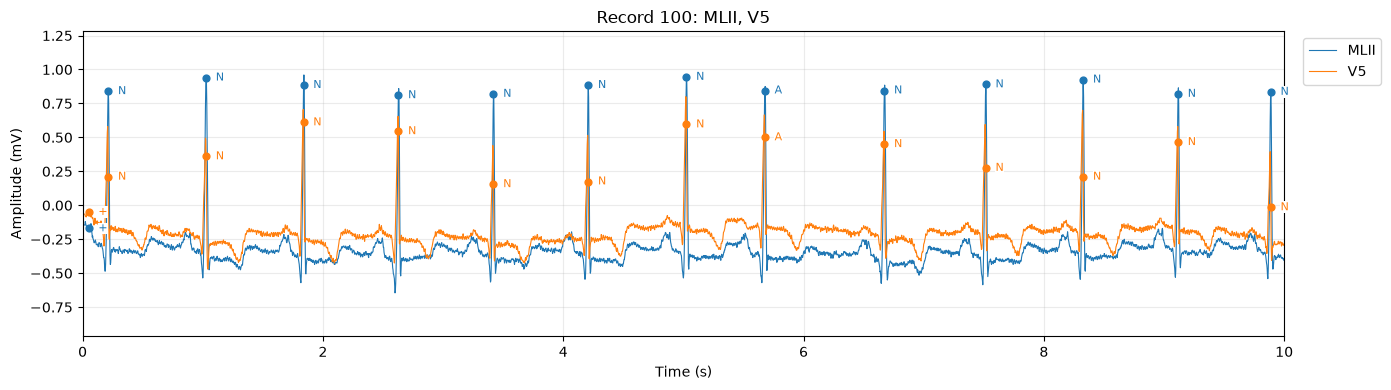

In [3]:
fig, ax = plot_ecg_with_annotations(
    record, annotations, channel=(0, 1), start_s=0, duration_s=10, layout="overlay"
)
plt.show()

### Example 2: one channel per row

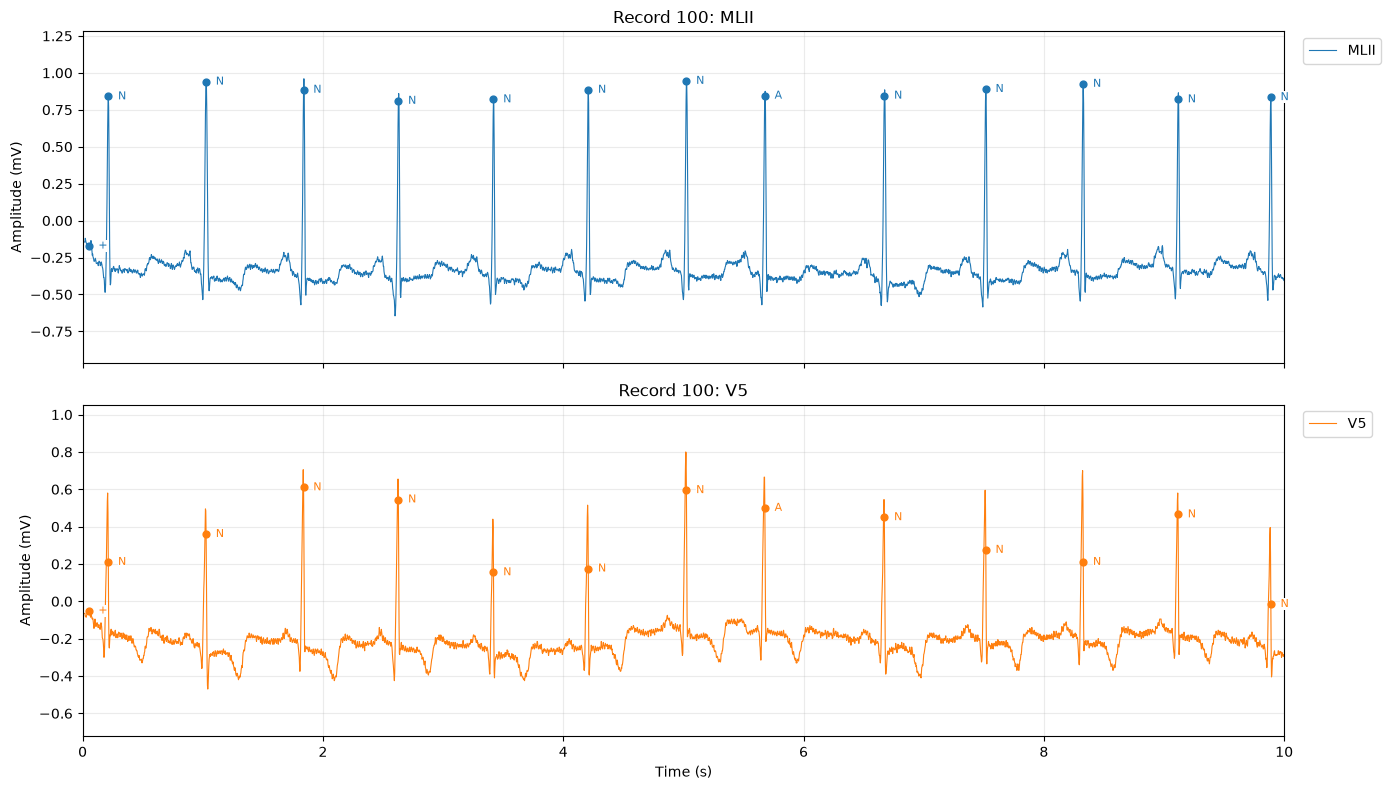

In [4]:
fig, axes = plot_ecg_with_annotations(
    record, annotations, channel=(0, 1), start_s=0, duration_s=10, layout="stacked"
)
plt.show()